# Credit Card Customer Segmentation
EDA -> preprocessing -> choose k -> compare algorithms -> profile clusters.
Open in VS Code (Python extension) and run cell by cell, or `jupytext --to ipynb` to convert.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture

from src.preprocess import RAW_FEATURES, build_preprocessor, load_data
from src.segments import PROFILE_COLS, profile_clusters

sns.set_theme(style="whitegrid")
SEED = 42

## 1. EDA

In [2]:
df = load_data()
print(df.shape)
df.head()

(8950, 18)


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [3]:
# Missing values: MINIMUM_PAYMENTS (~313) and CREDIT_LIMIT (1)
df.isna().sum()[lambda s: s > 0]

CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

In [4]:
df[RAW_FEATURES].describe().T

,count,mean,std,min,25%,50%,75%,max
BALANCE,8950.0,1564.474828,2081.531879,0.000000,128.281915,873.385231,2054.140036,19043.13856
BALANCE_FREQUENCY,8950.0,0.877271,0.236904,0.000000,0.888889,1.000000,1.000000,1.00000
PURCHASES,8950.0,1003.204834,2136.634782,0.000000,39.635000,361.280000,1110.130000,49039.57000
ONEOFF_PURCHASES,8950.0,592.437371,1659.887917,0.000000,0.000000,38.000000,577.405000,40761.25000
INSTALLMENTS_PURCHASES,8950.0,411.067645,904.338115,0.000000,0.000000,89.000000,468.637500,22500.00000
CASH_ADVANCE,8950.0,978.871112,2097.163877,0.000000,0.000000,0.000000,1113.821139,47137.21176
PURCHASES_FREQUENCY,8950.0,0.490351,0.401371,0.000000,0.083333,0.500000,0.916667,1.00000
ONEOFF_PURCHASES_FREQUENCY,8950.0,0.202458,0.298336,0.000000,0.000000,0.083333,0.300000,1.00000
PURCHASES_INSTALLMENTS_FREQUENCY,8950.0,0.364437,0.397448,0.000000,0.000000,0.166667,0.750000,1.00000
CASH_ADVANCE_FREQUENCY,8950.0,0.135144,0.200121,0.000000,0.000000,0.000000,0.222222,1.50000


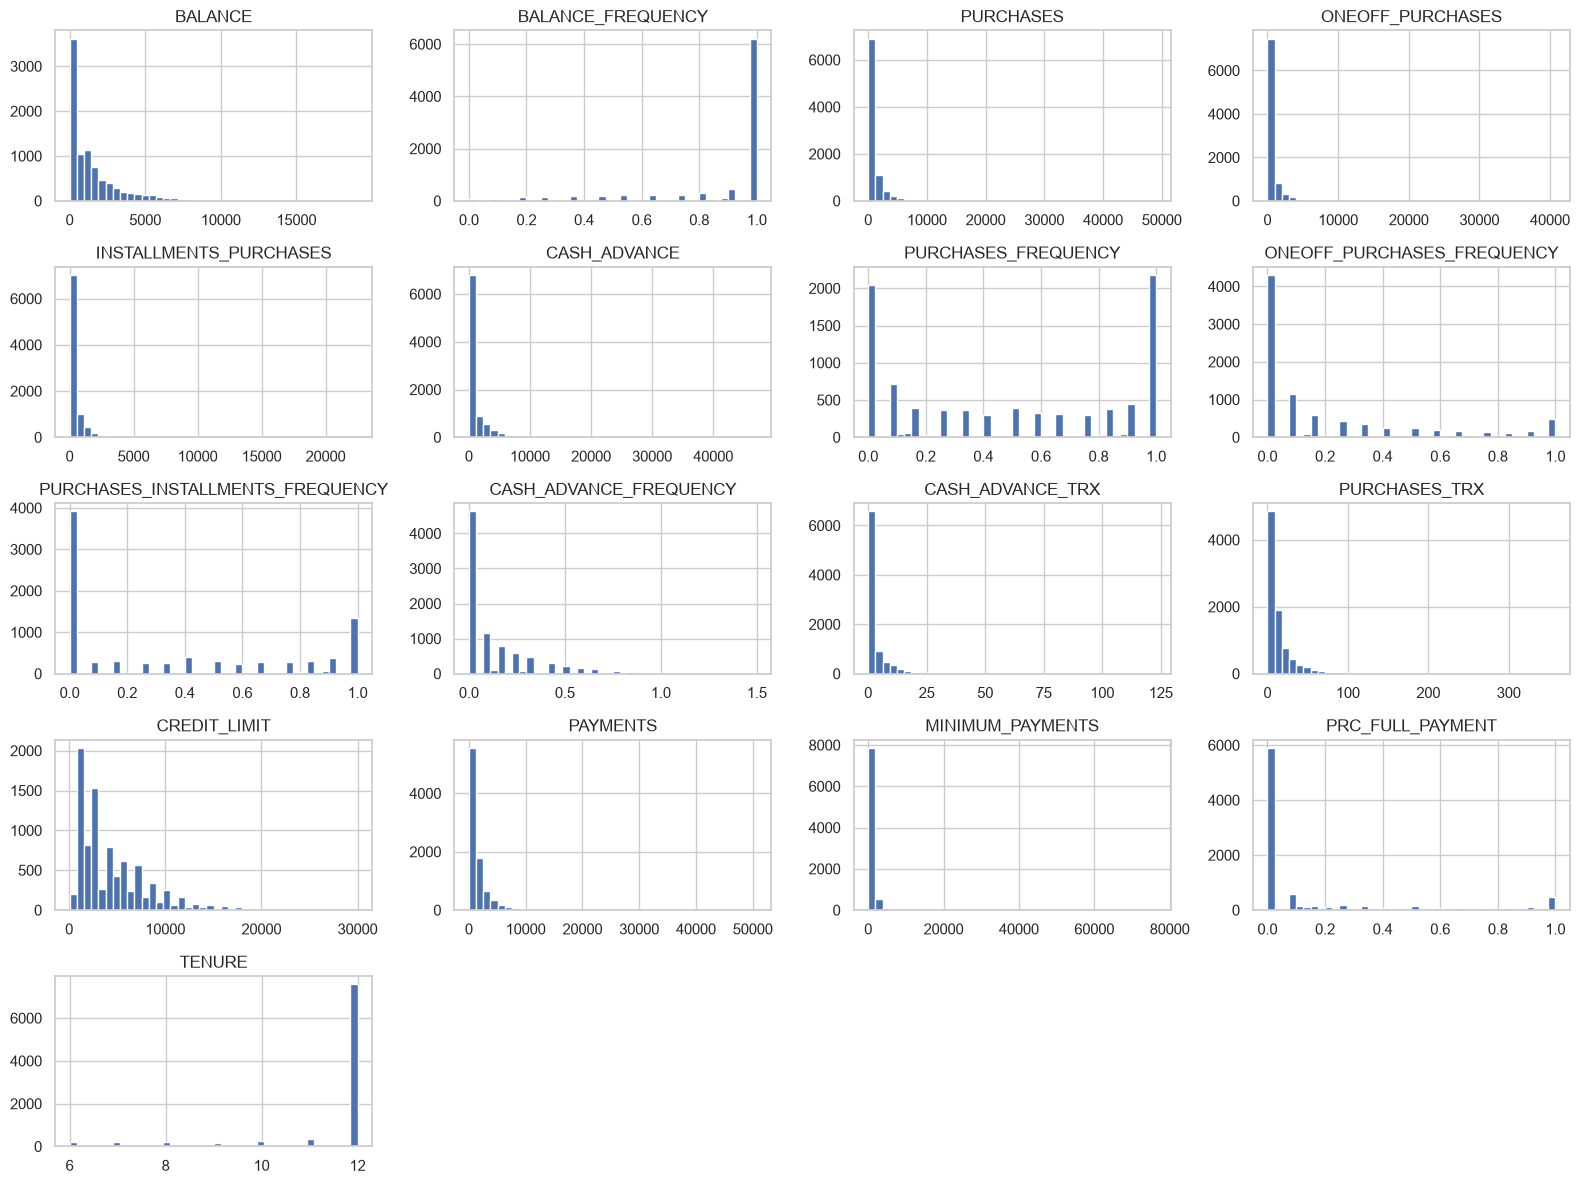

In [5]:
# Skewness -> motivates log1p
df[RAW_FEATURES].hist(bins=40, figsize=(16, 12))
plt.tight_layout()
plt.show()

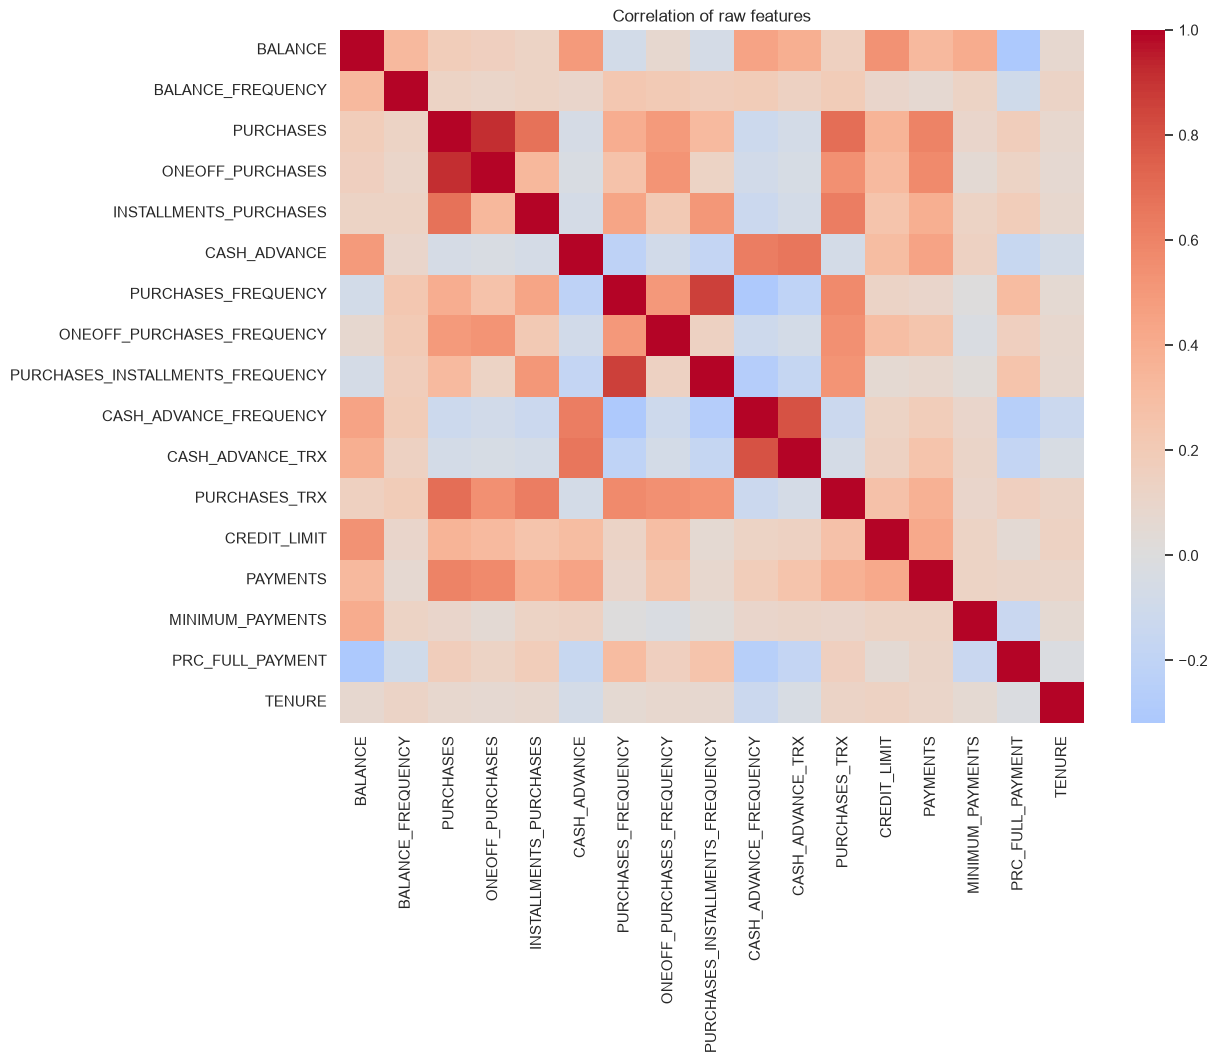

In [6]:
plt.figure(figsize=(12, 9))
sns.heatmap(df[RAW_FEATURES].corr(), cmap="coolwarm", center=0, annot=False)
plt.title("Correlation of raw features")
plt.show()

## 2. Preprocessing (feature engineering + log1p + median impute + scale + PCA 90%)

In [7]:
prep = build_preprocessor()
X = prep.fit_transform(df)
print(X.shape)

(8950, 9)


## 3. Choose k for K-Means

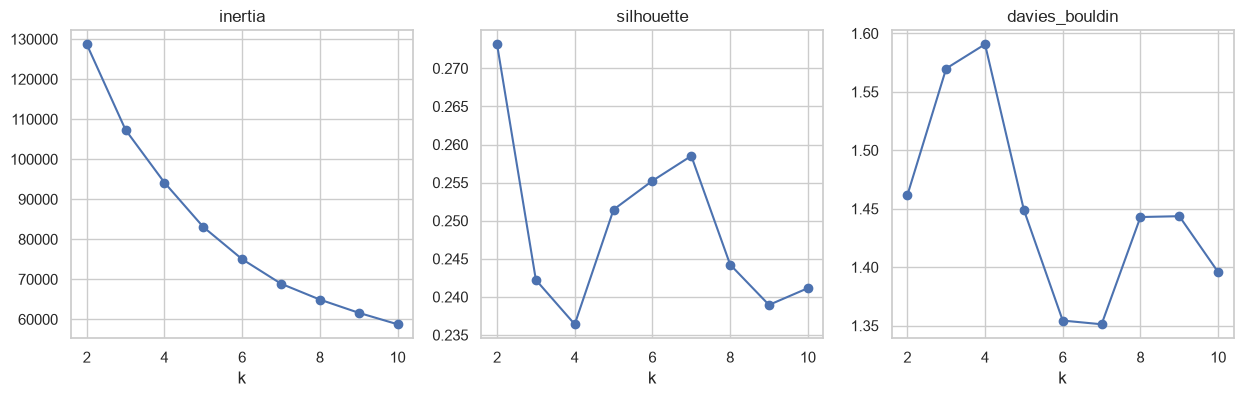

,k,inertia,silhouette,davies_bouldin
0,2,128709.274,0.273,1.461
1,3,107313.404,0.242,1.570
2,4,94156.199,0.236,1.591
3,5,83062.248,0.251,1.449
4,6,75020.276,0.255,1.354
5,7,68893.165,0.259,1.351
6,8,64927.044,0.244,1.443
7,9,61627.418,0.239,1.444
8,10,58757.532,0.241,1.396


In [8]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    rows.append(
        dict(
            k=k,
            inertia=km.inertia_,
            silhouette=silhouette_score(X, km.labels_, sample_size=5000, random_state=SEED),
            davies_bouldin=davies_bouldin_score(X, km.labels_),
        )
    )
scores = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["inertia", "silhouette", "davies_bouldin"]):
    ax.plot(scores["k"], scores[col], marker="o")
    ax.set_title(col)
    ax.set_xlabel("k")
plt.show()
scores.round(3)

In [9]:
# Composite k selection used by src.train: rank of silhouette + Davies-Bouldin + bootstrap stability
from src.train import select_k

K, k_table = select_k(X)
print('selected k:', K)
k_table.round(3)

selected k: 7


,k,silhouette,davies_bouldin,stability,min_share,rank_score
0,3,0.242,1.570,0.983,0.284,14.0
1,4,0.236,1.591,0.990,0.214,13.0
2,5,0.251,1.449,0.953,0.035,13.0
3,6,0.255,1.354,0.984,0.035,7.0
4,7,0.259,1.351,0.983,0.034,7.0
5,8,0.244,1.443,0.987,0.034,9.0


## 4. Compare algorithms

In [10]:
candidates = {
    "KMeans": KMeans(n_clusters=K, n_init=20, random_state=SEED),
    "GaussianMixture": GaussianMixture(n_components=K, random_state=SEED),
    "Agglomerative (Ward)": AgglomerativeClustering(n_clusters=K, linkage="ward"),
    "DBSCAN": DBSCAN(eps=1.5, min_samples=30),
}
results, all_labels = [], {}
for name, model in candidates.items():
    labels = model.fit_predict(X)
    all_labels[name] = labels
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    mask = labels != -1
    ok = n_clusters > 1 and mask.sum() > n_clusters
    results.append(
        dict(
            model=name,
            clusters=n_clusters,
            noise=int((~mask).sum()),
            silhouette=silhouette_score(X[mask], labels[mask], sample_size=5000, random_state=SEED) if ok else np.nan,
            davies_bouldin=davies_bouldin_score(X[mask], labels[mask]) if ok else np.nan,
        )
    )
pd.DataFrame(results).round(3)

,model,clusters,noise,silhouette,davies_bouldin
0,KMeans,7,0,0.259,1.351
1,GaussianMixture,7,0,0.154,1.740
2,Agglomerative (Ward),7,0,0.212,1.529
3,DBSCAN,2,1693,0.204,0.886


## 5. Stability check (adjusted Rand index across seeds)

In [11]:
from sklearn.metrics import adjusted_rand_score

ref = KMeans(n_clusters=K, n_init=20, random_state=0).fit_predict(X)
aris = [
    adjusted_rand_score(ref, KMeans(n_clusters=K, n_init=20, random_state=s).fit_predict(X))
    for s in range(1, 8)
]
print("ARI vs seed 0:", np.round(aris, 3))

ARI vs seed 0: [0.995 0.996 0.996 0.999 0.999 0.998 0.998]


## 6. Visualise in 2-D (PCA)

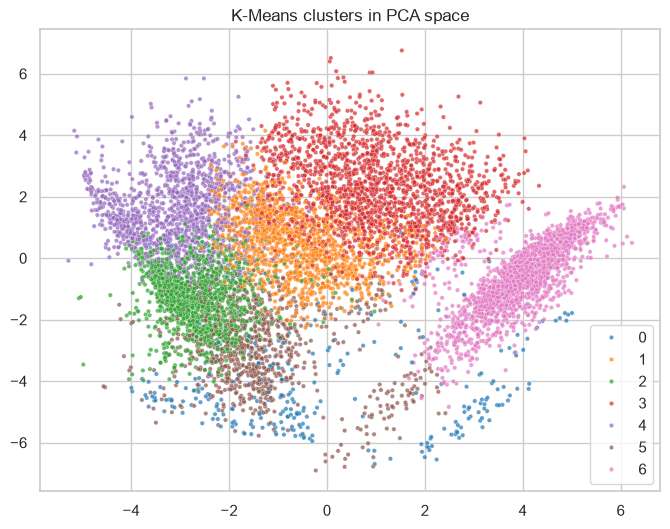

In [12]:
labels = all_labels["KMeans"]
coords = PCA(n_components=2, random_state=SEED).fit_transform(X)
plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=labels, palette="tab10", s=10, alpha=0.7)
plt.title("K-Means clusters in PCA space")
plt.show()

## 7. Profile clusters

In [13]:
segments = profile_clusters(df, labels)
profile = pd.DataFrame({s["name"]: s["profile"] for s in segments.values()}).T
profile.insert(0, "size", [s["size"] for s in segments.values()])
profile

,size,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,CREDIT_LIMIT,PAYMENTS,PURCHASES_FREQUENCY,CASH_ADVANCE_FREQUENCY,PRC_FULL_PAYMENT,TENURE
Low Payers,302,575.318,380.360,239.197,141.163,577.120,3704.801,76.836,0.336,0.069,0.000,11.043
Mainstream,1371,1462.288,676.242,386.412,290.199,15.959,3058.023,948.241,0.495,0.011,0.008,11.741
Full Payers (Transactors),1312,103.254,672.183,41.254,632.163,12.532,3263.361,738.676,0.842,0.004,0.445,11.328
Revolvers,1731,3088.680,1203.103,717.707,485.601,2490.028,5496.043,2625.532,0.615,0.328,0.034,11.441
Big Spenders,1339,1321.716,3443.120,2333.152,1110.005,44.459,7006.751,3179.167,0.913,0.011,0.330,11.886
Low Activity,899,59.785,397.328,307.072,90.333,117.340,4018.805,1228.310,0.229,0.022,0.241,11.498
Cash Advance Users,1996,2263.532,2.343,1.845,0.542,2040.594,4069.800,1659.970,0.006,0.283,0.031,11.387


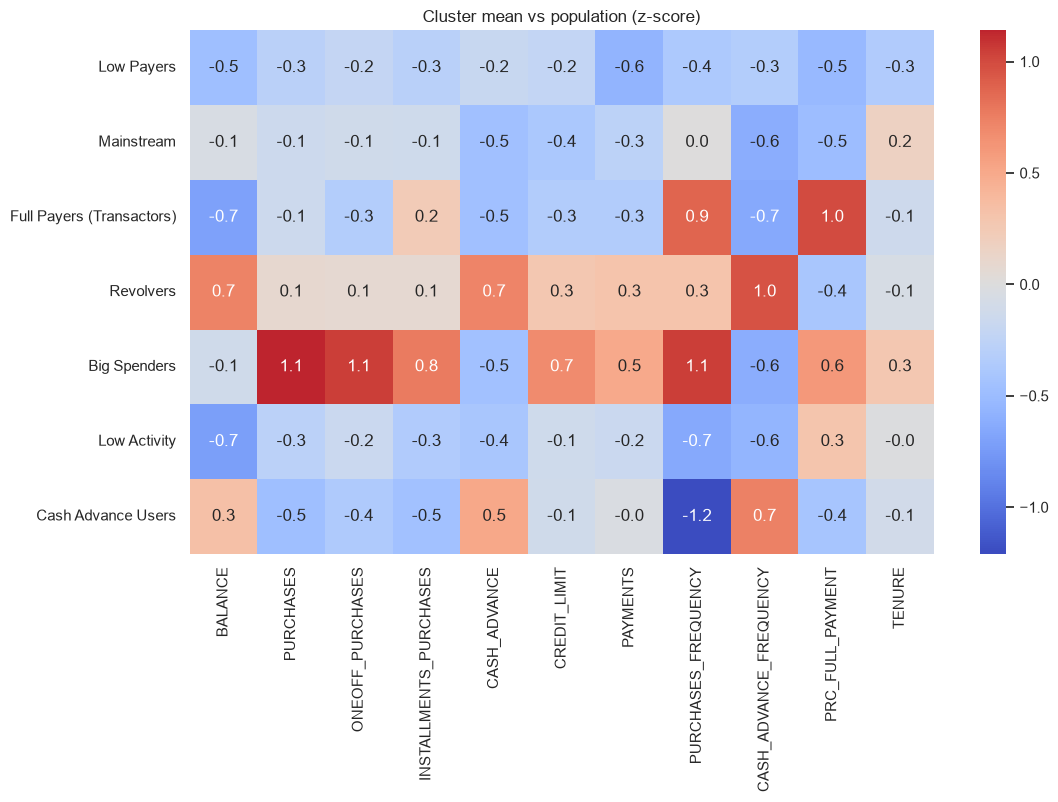

In [14]:
z = pd.DataFrame({s["name"]: s["zscore"] for s in segments.values()}).T
plt.figure(figsize=(12, 4 + 0.4 * len(z)))
sns.heatmap(z[PROFILE_COLS], annot=True, fmt=".1f", cmap="coolwarm", center=0)
plt.title("Cluster mean vs population (z-score)")
plt.show()

## 8. Hierarchical clustering deep-dive + lessons from a reference Kaggle notebook
Reference: the Kaggle notebook *Credit Card Customer Clustering* by caesarmario (K-Means / DBSCAN / Ward on PCA 2-D, k=4).
We reuse its good ideas (Hopkins test, dendrogram, per-cluster silhouette, richer marketing ideas) and test its claims fairly.

### 8.1 Hopkins test - is there any clustering tendency?
The reference reports Hopkins = 0.966 and concludes "meaningful clusters". A raw value is misleading on skewed data,
so we also compute it on a **column-shuffled copy** (same distributions, no structure). Only the *gap* means anything.

In [15]:
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from src.evaluation import hopkins_vs_null

# reference-notebook style space: raw scale (no log), KNN-imputed, standardised, then PCA 2-D
raw_num = df.drop(columns="CUST_ID")
nulls = raw_num.columns[raw_num.isna().any()].tolist()
raw_num = raw_num.fillna(pd.DataFrame(KNNImputer().fit_transform(raw_num[nulls]), columns=nulls))
X_ref = StandardScaler().fit_transform(raw_num)
X_ref2 = PCA(n_components=2, random_state=24).fit_transform(X_ref)

spaces = {
    "reference style: raw scale (17-D)": X_ref,
    "reference style: PCA 2-D": X_ref2,
    "this project: log + scaled + PCA (9-D)": X,
}
pd.DataFrame([{"space": name, **hopkins_vs_null(M)} for name, M in spaces.items()])

,space,hopkins,hopkins_null,hopkins_gap
0,reference style: raw scale (17-D),0.9653,0.9460,0.0192
1,reference style: PCA 2-D,0.9883,0.9921,-0.0038
2,this project: log + scaled + PCA (9-D),0.8747,0.7446,0.1301


**Reading it:** on the reference's raw-scale space the shuffled data scores almost the same as the real data (gap ~0),
so its 0.966 does not prove clusters. After log-transforming, the real data clearly beats the shuffled baseline,
i.e. there is genuine - but moderate - structure. This matches the low silhouette (~0.25) we see everywhere.

### 8.2 Dendrogram and choosing k for Ward

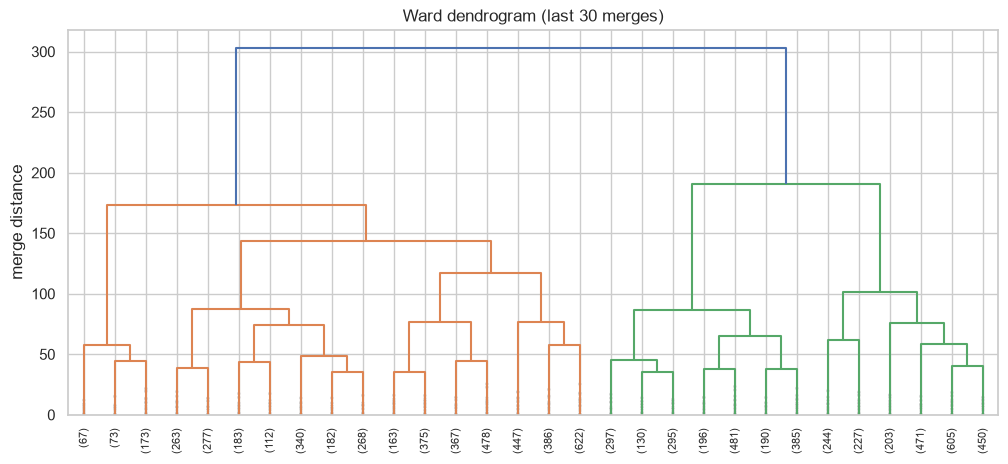

,k,merge_cost_to_k_minus_1,calinski_harabasz,silhouette,davies_bouldin
0,2,302.878,3074.827,0.250,1.602
1,3,190.918,2487.709,0.212,1.548
2,4,173.431,2354.657,0.241,1.382
3,5,143.520,2224.195,0.211,1.583
4,6,117.259,2074.543,0.208,1.522
5,7,101.552,1941.717,0.212,1.529
6,8,87.404,1815.848,0.207,1.500
7,9,86.368,1732.202,0.197,1.575
8,10,76.880,1650.657,0.187,1.534


In [16]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

Z = linkage(X, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_contracted=True, leaf_rotation=90, leaf_font_size=8)
plt.title("Ward dendrogram (last 30 merges)")
plt.ylabel("merge distance")
plt.show()

def hier_labels(M, k, method="ward", Zm=None):
    Zm = linkage(M, method=method) if Zm is None else Zm
    return fcluster(Zm, k, criterion="maxclust") - 1

rows = []
for k in range(2, 11):
    lab = hier_labels(X, k, Zm=Z)
    rows.append(dict(
        k=k,
        merge_cost_to_k_minus_1=Z[-(k - 1), 2],
        calinski_harabasz=calinski_harabasz_score(X, lab),
        silhouette=silhouette_score(X, lab, sample_size=5000, random_state=SEED),
        davies_bouldin=davies_bouldin_score(X, lab),
    ))
pd.DataFrame(rows).round(3)

### 8.3 Linkage comparison (and why Ward is the only sensible one here)

In [17]:
rows = []
for method in ["ward", "complete", "average", "single"]:
    Zm = linkage(X, method=method)
    for k in range(4, 9):
        lab = hier_labels(X, k, Zm=Zm)
        rows.append(dict(
            linkage=method, k=k,
            smallest_cluster_pct=100 * np.bincount(lab).min() / len(lab),
            silhouette=silhouette_score(X, lab, sample_size=5000, random_state=SEED),
            davies_bouldin=davies_bouldin_score(X, lab),
        ))
link_table = pd.DataFrame(rows).round(3)
link_table.pivot(index="k", columns="linkage", values="smallest_cluster_pct")

linkage,average,complete,single,ward
k,,,,
4,0.011,0.011,0.011,3.497
5,0.011,0.011,0.011,3.497
6,0.011,0.011,0.011,3.497
7,0.011,0.011,0.011,3.497
8,0.011,0.011,0.011,3.497


In [18]:
link_table.pivot(index="k", columns="linkage", values="silhouette")

linkage,average,complete,single,ward
k,,,,
4,0.229,0.118,0.319,0.241
5,0.224,0.130,0.189,0.211
6,0.159,0.135,0.135,0.208
7,0.228,0.131,0.120,0.212
8,0.225,0.117,0.113,0.207


Complete / average / single linkage produce clusters containing ~0% of customers (a handful of outliers each). Their
higher silhouette comes from isolating those outliers, not from useful segments, so they are rejected.

### 8.4 Ward vs K-Means: stability and a hybrid
Hierarchical clustering has no `predict()` for new customers and is not stable under resampling. We test that, and a hybrid
(Ward centroids as K-Means starting points).

In [19]:
rng = np.random.RandomState(SEED)
rows = []
for k in range(4, 9):
    ward_full = hier_labels(X, k, Zm=Z)
    km_full = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    w_stab, k_stab = [], []
    for i in range(3):
        idx = np.sort(rng.choice(len(X), int(0.8 * len(X)), replace=False))
        w_stab.append(adjusted_rand_score(ward_full[idx], hier_labels(X[idx], k)))
        sub = KMeans(n_clusters=k, n_init=10, random_state=SEED + i + 1).fit(X[idx])
        k_stab.append(adjusted_rand_score(km_full.labels_[idx], sub.labels_))
    cent = np.vstack([X[ward_full == c].mean(0) for c in range(k)])
    hyb = KMeans(n_clusters=k, init=cent, n_init=1).fit(X)
    rows.append(dict(
        k=k,
        ward_stability=np.mean(w_stab), kmeans_stability=np.mean(k_stab),
        ward_db=davies_bouldin_score(X, ward_full), kmeans_db=davies_bouldin_score(X, km_full.labels_),
        ward_init_kmeans_db=davies_bouldin_score(X, hyb.labels_),
        ward_init_inertia=hyb.inertia_, plain_kmeans_inertia=km_full.inertia_,
    ))
pd.DataFrame(rows).round(3)

,k,ward_stability,kmeans_stability,ward_db,kmeans_db,ward_init_kmeans_db,ward_init_inertia,plain_kmeans_inertia
0,4,0.925,0.993,1.382,1.591,1.326,96283.371,94156.199
1,5,0.737,0.989,1.583,1.449,1.449,83062.332,83062.248
2,6,0.710,0.979,1.522,1.354,1.355,75020.689,75020.276
3,7,0.703,0.988,1.529,1.351,1.362,71820.369,68893.165
4,8,0.717,0.891,1.500,1.443,1.349,65779.527,64927.044


**Reading it:** K-Means is more stable and has lower Davies-Bouldin than Ward for k >= 5. Ward-initialised K-Means matches plain
K-Means at best (sometimes a worse local optimum, higher inertia), so the hybrid adds no value. **Decision:** keep K-Means in
production; use hierarchical clustering for exploration (dendrogram, how segments relate).

### 8.5 Are the reference's metrics comparable to ours?
It scores its 2-D PCA clusters *inside that same 2-D space* (silhouette 0.41, DB 0.80). A score only makes sense in the space
the clustering was built in, so we evaluate both solutions in all three spaces.

In [20]:
ref_km = KMeans(n_clusters=4, random_state=32, max_iter=500).fit_predict(X_ref2)
mine_km = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(X)

rows = []
for sol, lab in {"reference (k=4, PCA 2-D)": ref_km, f"this project (k={K}, 9-D)": mine_km}.items():
    for space, M in spaces.items():
        rows.append(dict(solution=sol, judged_in=space,
                         silhouette=silhouette_score(M, lab, sample_size=5000, random_state=SEED),
                         davies_bouldin=davies_bouldin_score(M, lab)))
cross = pd.DataFrame(rows).round(3)
print("ARI between the two segmentations:", round(adjusted_rand_score(ref_km, mine_km), 3))
cross

ARI between the two segmentations: 0.166


,solution,judged_in,silhouette,davies_bouldin
0,"reference (k=4, PCA 2-D)",reference style: raw scale (17-D),0.178,1.633
1,"reference (k=4, PCA 2-D)",reference style: PCA 2-D,0.401,0.800
2,"reference (k=4, PCA 2-D)",this project: log + scaled + PCA (9-D),0.073,1.938
3,"this project (k=7, 9-D)",reference style: raw scale (17-D),0.049,2.743
4,"this project (k=7, 9-D)",reference style: PCA 2-D,0.035,3.055
5,"this project (k=7, 9-D)",this project: log + scaled + PCA (9-D),0.259,1.351


**Reading it:** each solution wins only in the space it was optimised for, so the reference's 0.41 cannot be compared with
our ~0.26. The decision must rest on stability, outlier handling (we log-transform; the reference clusters raw skewed values, so a few
extreme customers drive its clusters) and business interpretability (7 actionable segments vs 4 coarse ones).

### 8.6 Per-cluster silhouette (idea from the reference)

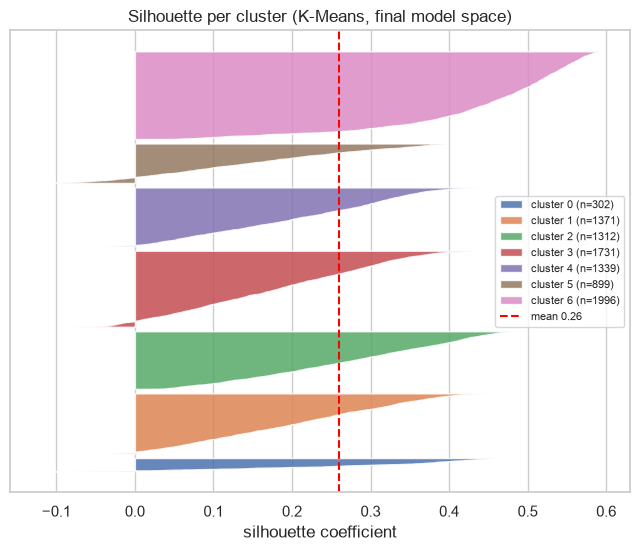

In [21]:
from sklearn.metrics import silhouette_samples

sil = silhouette_samples(X, mine_km)
fig, ax = plt.subplots(figsize=(8, 6))
y_low = 10
for c in range(K):
    v = np.sort(sil[mine_km == c])
    y_high = y_low + len(v)
    ax.fill_betweenx(np.arange(y_low, y_high), 0, v, alpha=0.85, label=f"cluster {c} (n={len(v)})")
    y_low = y_high + 100
ax.axvline(sil.mean(), color="red", ls="--", label=f"mean {sil.mean():.2f}")
ax.set_xlabel("silhouette coefficient"); ax.set_yticks([])
ax.set_title("Silhouette per cluster (K-Means, final model space)")
ax.legend(fontsize=8)
plt.show()

### 8.7 How do the segments relate? (dendrogram of segment centroids)

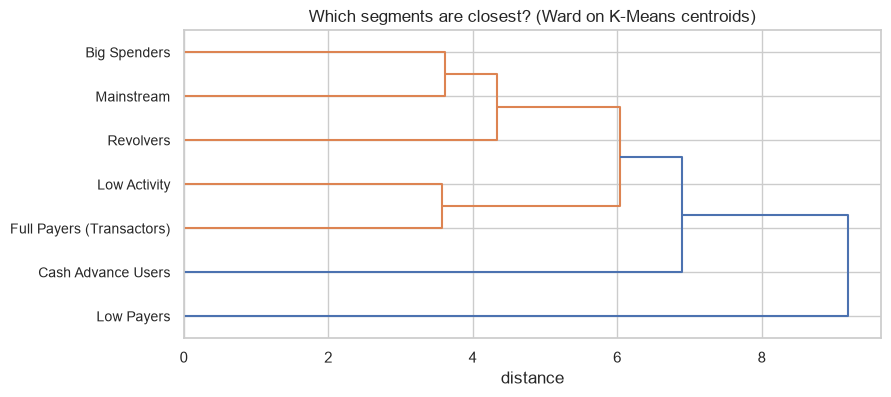

In [22]:
centroids = np.vstack([X[mine_km == c].mean(0) for c in range(K)])
seg_names = [segments[str(c)]["name"] if str(c) in segments else f"cluster {c}" for c in range(K)]
plt.figure(figsize=(9, 4))
dendrogram(linkage(centroids, method="ward"), labels=seg_names, orientation="right", leaf_font_size=10)
plt.title("Which segments are closest? (Ward on K-Means centroids)")
plt.xlabel("distance")
plt.show()

Note: cluster ids in this last plot come from a fresh K-Means fit, so segment names are matched by id and are indicative only
(the authoritative names/profiles are those saved by `python -m src.train`).

### 8.8 What we adopted from the reference
| Idea | Verdict |
|---|---|
| Hopkins test | Adopted, with a shuffled-data baseline (raw value alone is misleading); reported in `models/segments.json` |
| Dendrogram / hierarchical exploration | Adopted in this notebook; K-Means kept for production (stability, `predict()`) |
| Per-cluster silhouette plot | Adopted |
| Marketing ideas (rewards for active users, 0% instalment plans, entry-level cards for low-activity/students, cash-advance offers) | Merged into `src/segments.py` strategies |
| KNN imputation | Tested - same result as median (ARI 0.96, DB 1.345 vs 1.352), so kept median + missing flag (faster, simpler to serve) |
| PCA to 2-D before clustering | Rejected: loses information and inflates metrics; we keep 9 components (90% variance) and use 2-D only for plots |
| No log transform | Rejected: outliers dominate raw-scale clusters |

Next: `python -m src.train --k <K>` to save the pipeline, then `python -m app.app`.